In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(
    "../data/raw/pima-indians-diabetes.csv",
    header=None,
    names=columns
)

print("Đọc dữ liệu RAW thành công")
print("Kích thước:", df.shape)

display(df.head())

Đọc dữ liệu RAW thành công
Kích thước: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

print("Số feature:", len(features))
print(features)

Số feature: 8
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


## 1. Histogram các biến số

Histogram được sử dụng để quan sát hình dạng phân phối của 8 feature.


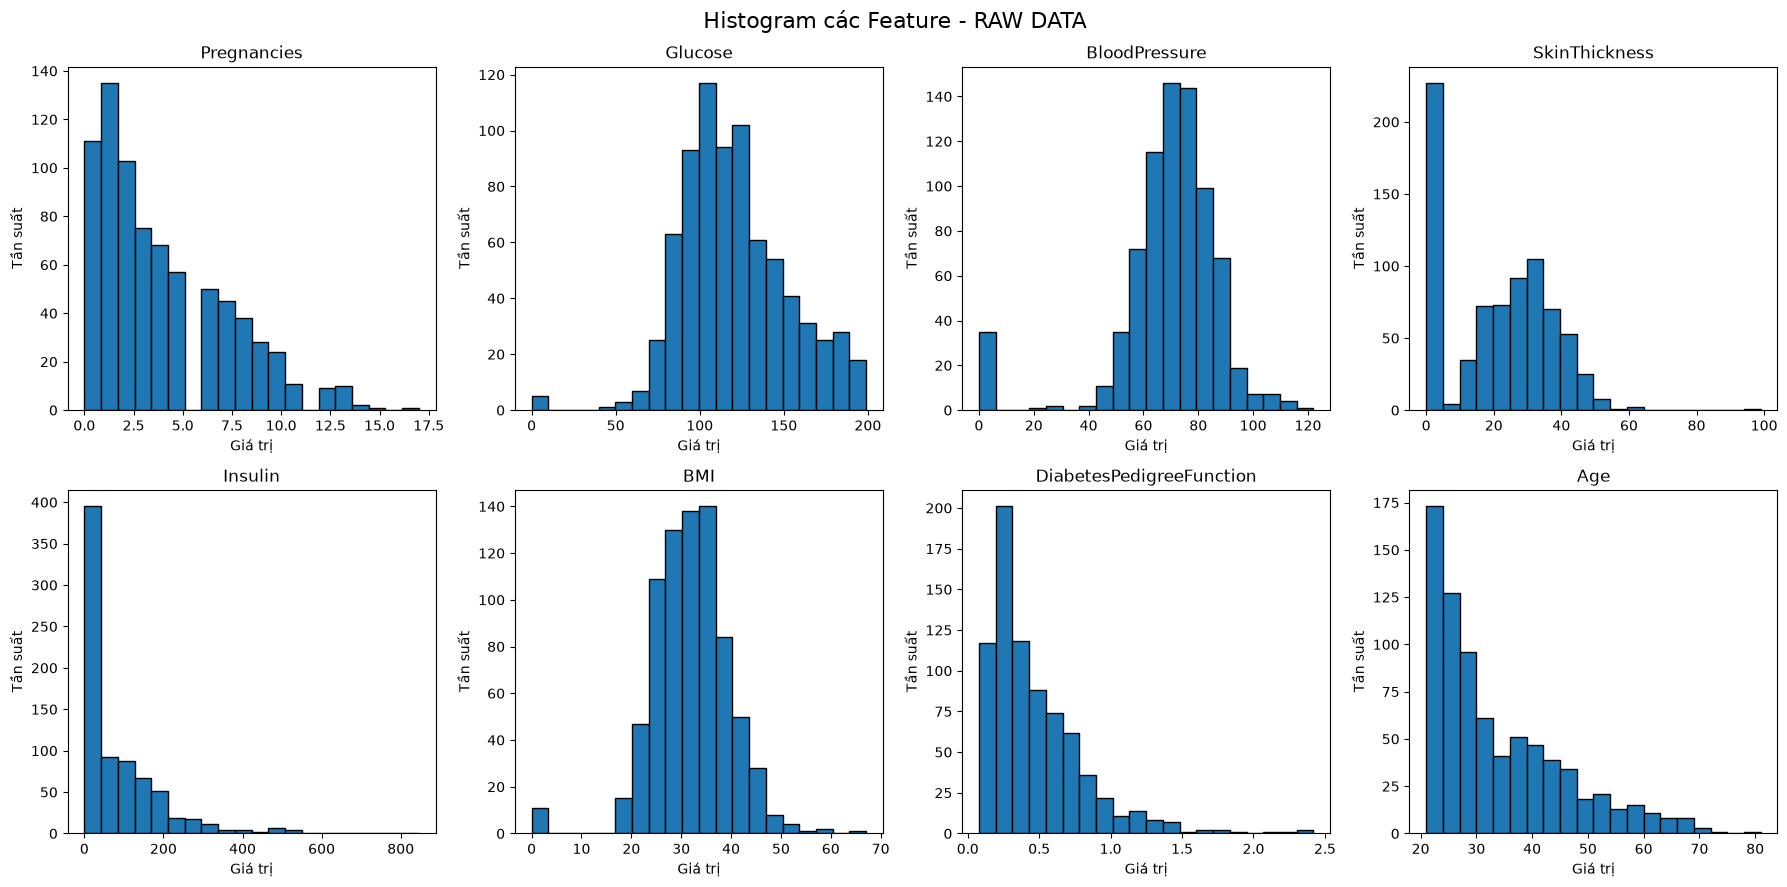

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].hist(
        df[col],
        bins=20,
        edgecolor="black"
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("Giá trị")
    axes[i].set_ylabel("Tần suất")

plt.suptitle(
    "Histogram các Feature - RAW DATA",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "../images/eda_raw/01_histogram_raw.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
print("NHẬN XÉT HISTOGRAM")
print()

print("- Pregnancies: phần lớn dữ liệu tập trung ở số lần mang thai thấp.")
print("- Glucose: dữ liệu tập trung chủ yếu ở vùng trung bình và có xuất hiện giá trị 0.")
print("- BloodPressure: phần lớn tập trung quanh vùng trung bình nhưng có giá trị 0.")
print("- SkinThickness: xuất hiện nhiều giá trị bằng 0.")
print("- Insulin: có nhiều giá trị 0 và phân bố lệch phải.")
print("- BMI: phần lớn tập trung trong một vùng chính nhưng có xuất hiện giá trị 0.")
print("- DiabetesPedigreeFunction: phần lớn tập trung ở các giá trị thấp.")
print("- Age: phần lớn mẫu tập trung ở nhóm tuổi thấp hơn.")

print()
print("Kết luận: Một số feature có phân bố lệch và xuất hiện giá trị 0.")
print("Các giá trị này chưa được xử lý trong Task 3.")

NHẬN XÉT HISTOGRAM

- Pregnancies: phần lớn dữ liệu tập trung ở số lần mang thai thấp.
- Glucose: dữ liệu tập trung chủ yếu ở vùng trung bình và có xuất hiện giá trị 0.
- BloodPressure: phần lớn tập trung quanh vùng trung bình nhưng có giá trị 0.
- SkinThickness: xuất hiện nhiều giá trị bằng 0.
- Insulin: có nhiều giá trị 0 và phân bố lệch phải.
- BMI: phần lớn tập trung trong một vùng chính nhưng có xuất hiện giá trị 0.
- DiabetesPedigreeFunction: phần lớn tập trung ở các giá trị thấp.
- Age: phần lớn mẫu tập trung ở nhóm tuổi thấp hơn.

Kết luận: Một số feature có phân bố lệch và xuất hiện giá trị 0.
Các giá trị này chưa được xử lý trong Task 3.


## 2. Boxplot các biến số

Boxplot được sử dụng để quan sát độ phân tán, phân phối lệch và các giá trị nằm xa phần lớn dữ liệu.


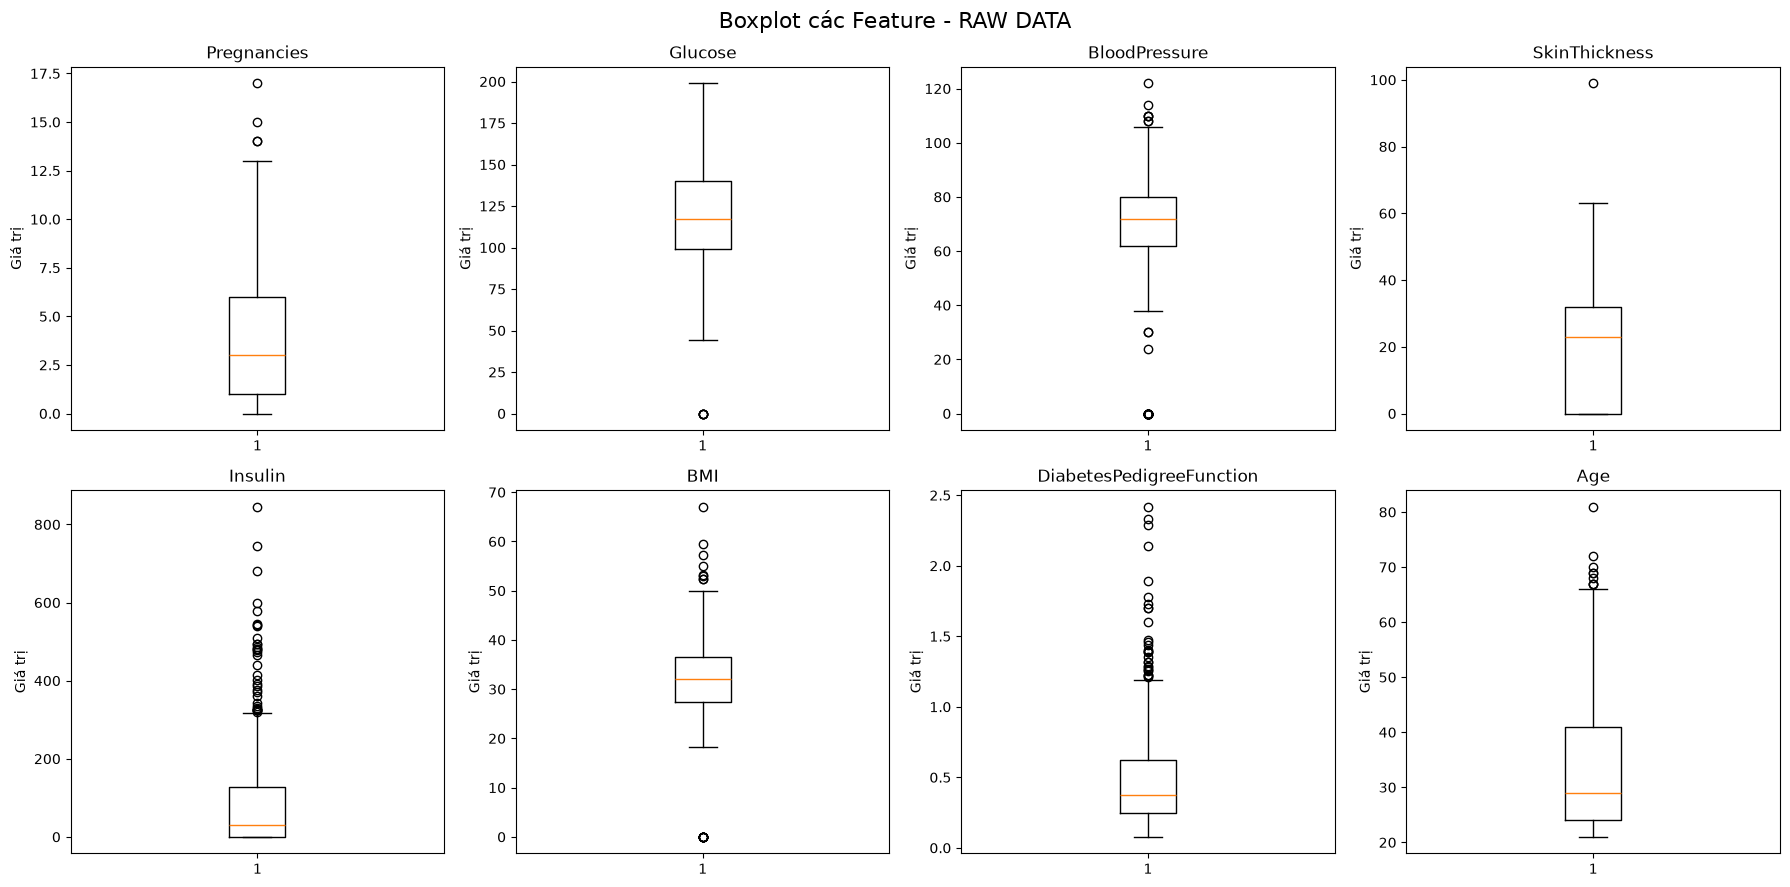

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].boxplot(df[col])

    axes[i].set_title(col)
    axes[i].set_ylabel("Giá trị")

plt.suptitle(
    "Boxplot các Feature - RAW DATA",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "../images/eda_raw/02_boxplot_raw.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
print("NHẬN XÉT BOXPLOT")
print()

print("- Pregnancies có một số giá trị cao.")
print("- Glucose xuất hiện một số giá trị rất thấp, bao gồm 0.")
print("- BloodPressure có giá trị 0 và một số giá trị cao.")
print("- SkinThickness xuất hiện nhiều giá trị 0.")
print("- Insulin có phạm vi rộng và nhiều giá trị cao.")
print("- BMI có một số giá trị cao và xuất hiện giá trị 0.")
print("- DiabetesPedigreeFunction có một số giá trị cao.")
print("- Age có một số mẫu ở nhóm tuổi cao.")

print()
print("Kết luận:")
print("Boxplot cho thấy một số thuộc tính có các điểm nằm xa phần lớn dữ liệu.")
print("Các điểm này chưa được loại bỏ vì Task 3 chỉ thực hiện EDA trên dữ liệu raw.")

NHẬN XÉT BOXPLOT

- Pregnancies có một số giá trị cao.
- Glucose xuất hiện một số giá trị rất thấp, bao gồm 0.
- BloodPressure có giá trị 0 và một số giá trị cao.
- SkinThickness xuất hiện nhiều giá trị 0.
- Insulin có phạm vi rộng và nhiều giá trị cao.
- BMI có một số giá trị cao và xuất hiện giá trị 0.
- DiabetesPedigreeFunction có một số giá trị cao.
- Age có một số mẫu ở nhóm tuổi cao.

Kết luận:
Boxplot cho thấy một số thuộc tính có các điểm nằm xa phần lớn dữ liệu.
Các điểm này chưa được loại bỏ vì Task 3 chỉ thực hiện EDA trên dữ liệu raw.


## 3. Phân bố biến mục tiêu Outcome

Outcome là nhãn của bài toán phân loại:

- Outcome = 0: Không mắc tiểu đường
- Outcome = 1: Mắc tiểu đường


In [8]:
outcome_count = df["Outcome"].value_counts().sort_index()

outcome_percent = (
    df["Outcome"]
    .value_counts(normalize=True)
    .sort_index() * 100
).round(2)

outcome_table = pd.DataFrame({
    "Outcome": [0, 1],

    "Ý nghĩa": [
        "Không mắc tiểu đường",
        "Mắc tiểu đường"
    ],

    "Số lượng": outcome_count.values,

    "Tỷ lệ (%)": outcome_percent.values
})

display(outcome_table)

,Outcome,Ý nghĩa,Số lượng,Tỷ lệ (%)
0,0,Không mắc tiểu đường,500,65.1
1,1,Mắc tiểu đường,268,34.9


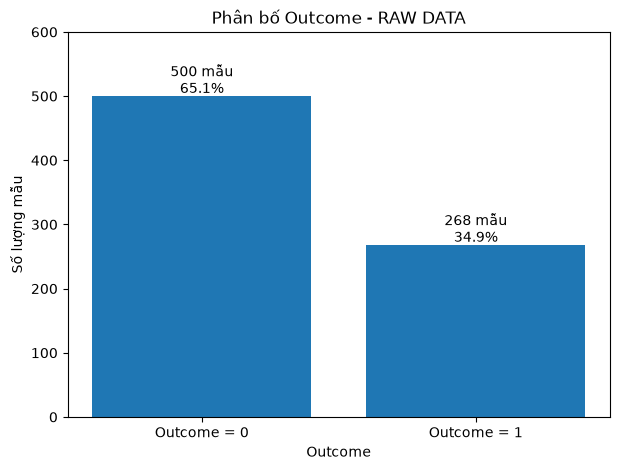

In [9]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Outcome = 0", "Outcome = 1"],
    outcome_count.values
)

plt.title("Phân bố Outcome - RAW DATA")
plt.xlabel("Outcome")
plt.ylabel("Số lượng mẫu")

for bar, count, percent in zip(
    bars,
    outcome_count.values,
    outcome_percent.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        f"{count} mẫu\n{percent}%",
        ha="center"
    )

plt.ylim(0, 600)

plt.savefig(
    "../images/eda_raw/03_outcome_distribution_raw.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
print("NHẬN XÉT PHÂN BỐ OUTCOME")
print()

print(f"Outcome = 0: {outcome_count[0]} mẫu ({outcome_percent[0]}%)")
print(f"Outcome = 1: {outcome_count[1]} mẫu ({outcome_percent[1]}%)")

print()
print("Kết luận:")
print("- Lớp 0 có số lượng mẫu lớn hơn lớp 1.")
print("- Có sự chênh lệch về số lượng giữa hai lớp.")
print("- Task 3 chỉ ghi nhận sự chênh lệch này, chưa thực hiện cân bằng dữ liệu.")

NHẬN XÉT PHÂN BỐ OUTCOME

Outcome = 0: 500 mẫu (65.1%)
Outcome = 1: 268 mẫu (34.9%)

Kết luận:
- Lớp 0 có số lượng mẫu lớn hơn lớp 1.
- Có sự chênh lệch về số lượng giữa hai lớp.
- Task 3 chỉ ghi nhận sự chênh lệch này, chưa thực hiện cân bằng dữ liệu.
